[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# [WEEK 8] Growth Analytics & Metric Design — Assignment
### "그렇다면, 프로모션을 줄이는 게 맞을까?"

## 과제 목적

발표에서는 **검색 → 예약완료 CVR 하락의 대부분이 믹스 시프트(프로모션 유입 비중 증가)** 때문이라는 결론을 냈습니다. 발표는 이 질문으로 끝났습니다.

> **그렇다면 프로모션을 줄이는 게 맞는가?**

이번 과제는 이 질문에서 시작합니다. 퀴즈에서 세운 가설을 **분석 전에 판정 기준과 함께 적어 두고**, 데이터로 하나씩 **지지 / 기각 / 판정 불가**를 내리면서 결론을 좁혀 갑니다.

> **가설 수립 → 예약의 질 → 반복 이용과 총 기여 → 순증 점검 → 캠페인 단위 drill-down → 판정과 운영 제안**

코드보다 **왜 다음 분석을 하는지**, 그리고 **앞 단계의 결과가 내 결론을 어떻게 바꿨는지**가 중요합니다.
---

## 📌 Business Question

> 프로모션 채널의 다음 운영 방향을 제안하세요. **줄일 것인가, 유지할 것인가, 무엇을 어떻게 바꿀 것인가?**
> 반복 이용, 예약의 질, 비용을 포함한 기여를 근거로 하고, 데이터로 확정할 수 없는 부분과 그 검증 방법까지 제시해주세요.

---

## ⚠️ 읽고 시작하기

- 이 데이터는 국내 숙박 예약 서비스를 가정한 **교육용 합성 데이터**입니다(2025-03 ~ 2026-08).
- **발표 슬라이드와 수치가 다릅니다.** 믹스 시프트라는 큰 구조는 같지만, 일부 결과는 발표와 다르게 나올 수 있습니다.
- 지표의 정확한 집계 규칙은 ZIP 안의 `METRIC_DEFINITIONS.md`, 컬럼 설명은 `DATA_DICTIONARY.md`에 있습니다. 노트북의 각 절에도 필요한 규칙을 적어 두었습니다.


## 빈칸 작성 방식

- 코드의 `__BLANK_n__`만 알맞은 코드로 바꾸면 됩니다. 셀 위의 주석이 힌트입니다.
- 앞에서 만든 변수를 뒤에서 계속 쓰므로 **위에서부터 순서대로** 실행하세요.
- 각 절의 **해석 문항**에 답하세요. 답에는 반드시 **본인이 출력한 수치**를 인용하세요.
- 주요 결과 아래의 `✅ / ❌` 자가 점검은 정답 값을 공개하지 않고 일치 여부만 알려 줍니다. ❌가 나오면 정의·필터·분모를 다시 확인하세요.


---
# 0. 환경 설정

1. 아래 셀을 실행하고 `growth_analytics_student_data.zip`을 업로드하세요. (Drive 연결·API 키 불필요)
2. 업로드한 파일이 배포본과 같은지 해시로 확인합니다.

### 데이터 한눈에 보기

| 테이블 | 한 행의 의미 | 주요 컬럼 |
|---|---|---|
| `users` | 가입 고객 1명 | `signed_up_at`, `acquisition_channel`(최초 획득 채널), `acquisition_campaign_id` |
| `sessions` | 검색 세션 1개 | `started_at`, `session_channel`(이번 방문 채널), `campaign_id`, `device` |
| `events` | 세션 안의 이벤트 1개 | `event_name`: search → list_view → detail_view → room_select → checkout_start → payment_complete |
| `bookings` | 예약 1건 (세션당 최대 1건) | `paid_at`, `gross_booking_amount_krw`, `platform_coupon_krw`, `commission_basis_points`, `status_at_cutoff`, `cancelled_at`, `completed_at` |
| `campaigns` | 캠페인 1개 | 검색광고 2(search_brand, search_category), 제휴 1(partner_program), 프로모션 2(**promo_destination, promo_open**) |
| `marketing_spend` | 일자 × 캠페인의 광고비 | `spend_date`, `campaign_id`, `media_cost_krw` |

### 공통 규칙 (모든 절에 적용)

- 모든 시각은 한국 시간(+09:00). 관찰 기간은 **2025-03-01 이상 ~ 2026-09-01 미만**.
- 비교 기간: **Before = 2025-03-01 ~ 2025-06-01 미만**, **After = 2026-03-01 ~ 2026-06-01 미만**.
- **채널 축 두 가지를 섞지 마세요.**
  - `session_channel`(이번 세션의 채널): §0의 세션 CVR에만 씁니다.
  - `acquisition_channel` / `acquisition_campaign_id`(고객을 처음 데려온 채널): §2 ~ §6 전부 이 축을 씁니다.
- **고객 결제액은 플랫폼 매출이 아닙니다.** 플랫폼 수익은 수수료(예약 총액의 12%)입니다.

In [1]:
# ── 0-1. 라이브러리 & 데이터 로딩 (수정하지 말고 실행) ─────────────────────
from pathlib import Path
import os, json, hashlib, zipfile, shutil, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = Path(os.environ.get("GROWTH_DATA_DIR", "growth_data/data"))
REQUIRED = ["users", "sessions", "events", "bookings", "campaigns", "marketing_spend"]

if not all((DATA_DIR / f"{name}.csv").exists() for name in REQUIRED):
    archive = Path("growth_analytics_student_data.zip")
    if not archive.exists():
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError("Colab에서는 학생용 데이터 ZIP을 업로드하세요. 로컬에서는 GROWTH_DATA_DIR 환경변수를 지정하세요.") from exc
        uploaded = files.upload()
        zips = [name for name in uploaded if name.endswith(".zip")]
        if len(zips) != 1:
            raise ValueError("growth_analytics_student_data.zip 파일 하나를 업로드하세요.")
        archive = Path(zips[0])
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for name in REQUIRED + ["manifest"]:
            member = f"data/{name}." + ("json" if name == "manifest" else "csv")
            with z.open(member) as src, (DATA_DIR / Path(member).name).open("wb") as dst:
                shutil.copyfileobj(src, dst)

# 파일 무결성 확인 (모든 학생이 같은 데이터를 쓰는지 확인)
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
for name, spec in manifest["tables"].items():
    digest = hashlib.sha256((DATA_DIR / f"{name}.csv").read_bytes()).hexdigest()
    assert digest == spec["sha256"], f"{name}.csv 가 배포본과 다릅니다."
print("✅ 데이터 확인 완료:", DATA_DIR)

Saving growth_analytics_student_data.zip to growth_analytics_student_data.zip
✅ 데이터 확인 완료: growth_data/data


In [2]:
# ── 0-2. 테이블 불러오기 & 공통 설정 (수정하지 말고 실행) ───────────────────
def to_kst(col):
    """+09:00 문자열 → 한국 시간 기준 naive datetime"""
    return pd.to_datetime(col, utc=True).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)

users     = pd.read_csv(DATA_DIR / "users.csv", dtype=str)
sessions  = pd.read_csv(DATA_DIR / "sessions.csv", dtype=str)
events    = pd.read_csv(DATA_DIR / "events.csv", dtype=str, usecols=["session_id", "event_name"])
bookings  = pd.read_csv(DATA_DIR / "bookings.csv", dtype={"booking_id": str, "session_id": str, "user_id": str})
campaigns = pd.read_csv(DATA_DIR / "campaigns.csv")
spend     = pd.read_csv(DATA_DIR / "marketing_spend.csv")

users["signed_up_at"] = to_kst(users["signed_up_at"])
users["acq_campaign"] = users["acquisition_campaign_id"].fillna("organic")   # 자연 유입은 'organic'
sessions["started_at"] = to_kst(sessions["started_at"])
for col in ["paid_at", "cancelled_at", "completed_at"]:
    bookings[col] = to_kst(bookings[col])
bookings["checkout_at"] = pd.to_datetime(bookings["check_out_date"]) + pd.Timedelta(hours=11)
spend["spend_date"] = pd.to_datetime(spend["spend_date"])

OBS_END = pd.Timestamp("2026-09-01")          # 관찰 종료(미포함)
PERIODS = {"Before": ("2025-03-01", "2025-06-01"),   # 이전 기간 [시작, 끝)
           "After":  ("2026-03-01", "2026-06-01")}   # 최근 기간 [시작, 끝)
WINDOW = pd.Timedelta(days=90)                 # 90 × 24시간
STAGES = ["search", "list_view", "detail_view", "room_select", "checkout_start", "payment_complete"]

def in_period(ts, period):
    """ts(Series)가 PERIODS[period] 구간 [시작, 끝)에 속하는지"""
    lo, hi = PERIODS[period]
    return (ts >= pd.Timestamp(lo)) & (ts < pd.Timestamp(hi))

# 예약 + 예약 고객의 최초 획득 채널/캠페인
book = bookings.merge(users[["user_id", "acquisition_channel", "acq_campaign"]], on="user_id", how="left")

import hashlib as _hl
def self_check(label, value, digest):
    """본인 결과가 정답과 같은지 확인합니다 (정답 값은 공개되지 않습니다)."""
    ok = _hl.sha256(str(value).encode()).hexdigest()[:12] == digest
    print(("✅ " if ok else "❌ ") + label + ("" if ok else " — 정의·필터·분모를 다시 확인하세요."))

for name, df in [("users", users), ("sessions", sessions), ("events", events), ("bookings", bookings),
                 ("campaigns", campaigns), ("marketing_spend", spend)]:
    print(f"{name:<16}{df.shape}")

users           (80200, 5)
sessions        (234175, 11)
events          (928870, 2)
bookings        (26213, 17)
campaigns       (5, 6)
marketing_spend (2745, 3)


---
# §0. 출발점 — 발표 결론 확인

발표와 같은 방식으로 세션 단위 CVR(같은 세션 안에서 search 이후 payment_complete가 발생한 세션 수 ÷ 검색 세션 수)을 Before / After로 비교하고, 변화를 **믹스 효과**와 **비율 효과**로 분해합니다.

,search_sessions,paid_sessions,cvr
period,,,
Before,"23,807","3,069",12.89%
After,"48,802","4,791",9.82%


전체 CVR 변화 -3.07%p = 믹스 효과 -2.90%p + 비율 효과 -0.18%p


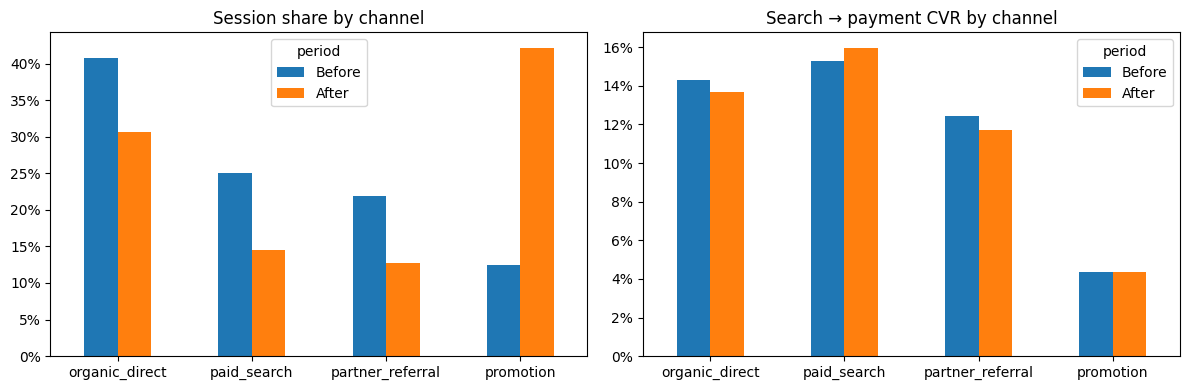

In [3]:
# ── §0. 발표 결론 재현: 세션 CVR과 믹스/비율 분해 (수정하지 말고 실행) ─────────
paid_sessions = set(events.loc[events["event_name"] == "payment_complete", "session_id"])
sessions["converted"] = sessions["session_id"].isin(paid_sessions)

rows = []
for period in PERIODS:
    x = sessions[in_period(sessions["started_at"], period)]
    g = (x.groupby("session_channel")
          .agg(search_sessions=("session_id", "size"), paid_sessions=("converted", "sum"))
          .reset_index())
    g["share"] = g["search_sessions"] / g["search_sessions"].sum()
    g["cvr"] = g["paid_sessions"] / g["search_sessions"]
    g["period"] = period
    rows.append(g)
seg = pd.concat(rows, ignore_index=True)

overall = seg.groupby("period")[["search_sessions", "paid_sessions"]].sum().reindex(list(PERIODS))
overall["cvr"] = overall["paid_sessions"] / overall["search_sessions"]
display(overall.style.format({"search_sessions": "{:,}", "paid_sessions": "{:,}", "cvr": "{:.2%}"}))

wide = (seg.pivot(index="session_channel", columns="period", values=["share", "cvr"])
          .reindex(columns=list(PERIODS), level=1))
display(wide.style.format("{:.2%}"))

# 믹스 효과 = Σ (After 비중 − Before 비중) × Before CVR
# 비율 효과 = Σ After 비중 × (After CVR − Before CVR)
mix_effect  = ((wide["share"]["After"] - wide["share"]["Before"]) * wide["cvr"]["Before"]).sum()
rate_effect = (wide["share"]["After"] * (wide["cvr"]["After"] - wide["cvr"]["Before"])).sum()
total_change = overall.loc["After", "cvr"] - overall.loc["Before", "cvr"]
print(f"전체 CVR 변화 {total_change*100:+.2f}%p = 믹스 효과 {mix_effect*100:+.2f}%p + 비율 효과 {rate_effect*100:+.2f}%p")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wide["share"].plot(kind="bar", ax=axes[0], title="Session share by channel")
wide["cvr"].plot(kind="bar", ax=axes[1], title="Search → payment CVR by channel")
for ax in axes:
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

프로모션의 CVR은 그대로인데 비중이 크게 늘어 전체 CVR이 떨어졌습니다.

> **그렇다면 프로모션을 줄이는 게 맞는가?**

지금부터는 해당 질문에 답합니다. 여기서부터는 **고객을 처음 데려온 채널(acquisition_channel)** 기준으로 봅니다.

---
# §1. 가설과 판단 기준 (서술, 코드 없음)

퀴즈 서술형에서 세운 가설 그룹화한 결과입니다.

| 가설 | 내용 | 검증에 쓸 지표 |
|---|---|---|
| **H1** | 프로모션 유입은 CVR·재예약률이 낮지만 모수가 커서, 절대 예약 건수와 기여는 오히려 늘었을 것이다 | 재예약률, 가입 후 90일 기여(총액/1인당), 완료 박 수 비중 |
| **H2** | 프로모션 유입 중 일부는 프로모션이 없어도 왔을 유저라서, 실제 순증 효과는 보이는 것보다 작을 것이다 | 노출군 vs 비노출군의 차이(순증) |
| **H3** | 프로모션 유입은 단가가 낮고 취소가 많아 예약의 질이 낮을 것이다 | 취소율, 객단가, 완료 박 수 |

분석 결과를 보고 기준을 바꾸는 일(사후 합리화)을 막기 위해, **분석 전에** 판단 기준을 먼저 적습니다.

### ❓ Q1

1. 아래 후보 중 "프로모션을 줄일지"를 결정할 **주 판단 지표**를 하나 고르고, **분자 / 분모 / 집계 단위 / 기간**을 정의하세요.
   후보: ① 세션 CVR ② 첫 예약 후 90일 재예약률 ③ 가입 후 90일 관찰 기여 ④ 월 완료 박 수 중 프로모션 비중
2. 각 가설이 참이라면 어떻게 되는지 한 문장으로 작성해주세요.

**A.** 1. ③ 가입 후 90일 관찰 기여 (Metric C), 분자: 90일 수수료 수익 − 쿠폰비 − 결제처리비 − 취소처리비 − 광고비, 분모: 해당 기간 신규 가입자 수, 집계 단위: 최초 획득 채널별 총액 및 가입자 1인당 기여, 기간: Before·After 가입자의 가입 후 90일. 2. H1: CVR·재예약률이 낮더라도 유입 규모가 커서 총 예약 건수와 기여는 증가할 것이다. H2: 프로모션 없이도 유입됐을 고객이 포함되어 실제 순증 효과는 관찰된 기여보다 작을 것이다. H3: 프로모션 고객은 객단가가 낮고 취소율이 높아 예약의 질이 낮을 것이다.

###가설 검증은 H3 -> H1 -> H2 순으로 진행되며, 모두 진행해주시면 됩니다.

---
# §2. 예약의 질 — H3 검증

**지표 정의 (Metric B)**

- 대상: `paid_at`이 비교 기간에 속하고, **원래 예정된 체크아웃(체크아웃일 11:00)이 관찰 종료 전**인 예약
  (체크아웃이 아직 오지 않은 예약은 앞으로 취소될 수도 있어 취소율을 왜곡하므로 제외합니다.)
- 취소율 = 대상 중 `cancelled` 예약 수 ÷ 대상 예약 수
- 완료 박 수 = 대상 중 `completed` 예약의 `nights` 합
- 객단가 = 대상 예약의 `gross_booking_amount_krw` 평균
- 그룹: **최초 획득 채널** · `ci95_pp`는 취소율의 95% 신뢰구간 반폭(%p)

In [4]:
# ── §2. 예약의 질: 최초 획득 채널별 취소율 · 객단가 · 완료 박 수 ──────────────
# 대상: paid_at이 비교 기간에 속하고, 예정 체크아웃(체크아웃일 11:00)이 관찰 종료 전인 예약
# 힌트: 예약 상태값은 DATA_DICTIONARY의 status_at_cutoff 설명을 참고하세요.

def booking_quality(period, by="acquisition_channel"):
    paid_in_period = book[in_period(book["paid_at"], period)]
    target = paid_in_period[paid_in_period["checkout_at"] < OBS_END].copy()   # 성숙도 필터
    print(f"[{period}] 결제 {len(paid_in_period):,}건 중 체크아웃이 관찰 종료 이후라 제외: {len(paid_in_period) - len(target):,}건")

    target["is_cancelled"] = target["status_at_cutoff"] == "cancelled"
    target["completed_nights"] = np.where(target["status_at_cutoff"] == "completed", target["nights"], 0)

    out = target.groupby(by).agg(
        bookings=("booking_id", "size"),
        cancelled=("is_cancelled", "sum"),
        aov_krw=("gross_booking_amount_krw", "mean"),
        completed_room_nights=("completed_nights", "sum"),
    )
    out["cancel_rate"] = out["cancelled"] / out["bookings"]
    out["ci95_pp"] = 1.96 * np.sqrt(out["cancel_rate"] * (1 - out["cancel_rate"]) / out["bookings"]) * 100
    return out

QUALITY_FMT = {"bookings": "{:,}", "cancelled": "{:,}", "aov_krw": "{:,.0f}",
               "completed_room_nights": "{:,}", "cancel_rate": "{:.1%}", "ci95_pp": "±{:.1f}%p"}
quality = {p: booking_quality(p) for p in PERIODS}
for p, q in quality.items():
    print(f"[{p}] 대상 예약 {q['bookings'].sum():,}건")
    display(q.style.format(QUALITY_FMT))
assert quality["After"]["cancel_rate"].between(0, 1).all(), "취소율은 0~1 사이여야 합니다."
self_check("§2 After 프로모션 취소율", f'{quality["After"].loc["promotion", "cancel_rate"]:.3f}', "896cba109aea")

[Before] 결제 3,069건 중 체크아웃이 관찰 종료 이후라 제외: 0건
[After] 결제 4,791건 중 체크아웃이 관찰 종료 이후라 제외: 0건
[Before] 대상 예약 3,069건


,bookings,cancelled,aov_krw,completed_room_nights,cancel_rate,ci95_pp
acquisition_channel,,,,,,
organic_direct,"1,336",104,"178,036","1,749",7.8%,±1.4%p
paid_search,931,97,"179,044","1,164",10.4%,±2.0%p
partner_referral,666,49,"175,774",877,7.4%,±2.0%p
promotion,136,7,"186,729",185,5.1%,±3.7%p


[After] 대상 예약 4,791건


,bookings,cancelled,aov_krw,completed_room_nights,cancel_rate,ci95_pp
acquisition_channel,,,,,,
organic_direct,"1,702",138,"186,887","2,288",8.1%,±1.3%p
paid_search,"1,243",121,"179,755","1,596",9.7%,±1.6%p
partner_referral,832,59,"186,742","1,129",7.1%,±1.7%p
promotion,"1,014",68,"181,451","1,295",6.7%,±1.5%p


✅ §2 After 프로모션 취소율


### ❓ Q2

1. After 기준으로 프로모션의 **취소율과 객단가**를 다른 채널과 비교하고, **H3을 판정**하세요(지지 / 기각 / 판정 불가). 신뢰구간(`ci95_pp`)을 함께 고려하세요.
2. Before 기간의 프로모션 예약은 몇 건인가요? 이 표본으로 Before → After 변화를 해석할 때 어떤 위험이 있나요? 판정은 어느 기간 기준으로 하는 것이 적절할까요? 덧붙여, 이번 비교 기간에서 성숙도 필터로 빠진 예약은 몇 건이었나요? 0건이라도 이 필터를 코드에 두어야 하는 이유는?

**A.**1. After 프로모션의 취소율은 6.7%(95% 신뢰구간 약 5.2~8.2%)로 다른 채널(7.1~9.7%)보다 낮았다. 객단가는 181,451원으로 일부 채널보다 낮지만, 가장 낮지는 않았다. 따라서 예약의 질이 낮다는 H3은 지지되지 않는다. 2. Before 프로모션 예약은 136건으로 표본이 적어 취소율의 불확실성(±3.7%p)이 크다. After는 1,014건(±1.5%p)이므로 이를 중심으로 판단한다. 성숙도 필터 제외 건수는 Before·After 모두 0건이다. 필터는 아직 체크아웃하지 않은 예약으로 인한 취소율 왜곡을 방지한다.

---
# §3. 반복 이용과 총 기여 — H1 검증

## 3-A. 첫 예약 후 90일 이내 누적 재예약률 (Metric A)

- 코호트: 각 고객의 **생애 첫** 결제 시각(`first_paid_at`)이 비교 기간에 속하는 고객 (기간 안의 첫 결제가 아닙니다!)
- 분자: `(first_paid_at, first_paid_at + 90일]` 안에 **다른 예약을 결제한** 고객 수 — 첫 예약 자체는 제외, 취소 후 다시 결제한 경우도 포함
- 분모: `first_paid_at + 90일`이 관찰 종료 이전인 고객만 (90일을 끝까지 관찰한 고객)
- 발표는 6개월 rolling 재예약률을 썼지만, 여기서는 비교 기간 코호트가 모두 끝까지 관찰되는 **90일**을 씁니다.

In [5]:
# ── §3-A. 반복 이용: 첫 예약 후 90일 이내 누적 재예약률 ─────────────────────────
# 코호트: 각 고객의 '생애 첫' 결제 시각(first_paid_at)이 비교 기간에 속하는 고객
# 분자: (first_paid_at, first_paid_at + 90일] 안에 다른 예약을 결제한 고객 (첫 예약 자체는 제외)
# 분모: first_paid_at + 90일이 관찰 종료 이전인 고객만 (성숙한 코호트)

first_paid = (bookings.groupby("user_id", as_index=False)["paid_at"].min()
                      .rename(columns={"paid_at": "first_paid_at"}))

rb = bookings[["user_id", "booking_id", "paid_at"]].merge(first_paid, on="user_id")
rb["is_rebook"] = (rb["paid_at"] > rb["first_paid_at"]) & (rb["paid_at"] <= rb["first_paid_at"] + WINDOW)

cust = (rb.groupby("user_id", as_index=False)
          .agg(first_paid_at=("first_paid_at", "first"), rebooked=("is_rebook", "any"))
          .merge(users[["user_id", "acquisition_channel", "acq_campaign"]], on="user_id", how="left"))
mature = cust["first_paid_at"] + WINDOW <= OBS_END                      # 성숙도 필터: 90일을 끝까지 관찰한 고객만
print(f"90일을 다 관찰하지 못해 분모에서 빠진 고객: 전체 {(~mature).sum():,}명 "
      f"(그중 비교 기간 코호트: {(~mature & (in_period(cust['first_paid_at'], 'Before') | in_period(cust['first_paid_at'], 'After'))).sum():,}명)")
cust = cust[mature]
assert cust["user_id"].is_unique, "고객 1명 = 1행이어야 합니다."

def rebook_table(by="acquisition_channel"):
    parts = []
    for p in PERIODS:
        x = cust[in_period(cust["first_paid_at"], p)]
        g = x.groupby(by).agg(customers=("rebooked", "size"), rebooked=("rebooked", "sum"))
        g["rebook_rate"] = g["rebooked"] / g["customers"]
        g.columns = pd.MultiIndex.from_product([[p], g.columns])
        parts.append(g)
    t = pd.concat(parts, axis=1)
    t[("diff", "pp")] = (t[("After", "rebook_rate")] - t[("Before", "rebook_rate")]) * 100
    return t

rebook = rebook_table()
assert (rebook.xs("rebooked", axis=1, level=1) <= rebook.xs("customers", axis=1, level=1)).all().all()
_after = cust[in_period(cust["first_paid_at"], "After")]
self_check("§3-A After 전체 재예약률", f'{_after["rebooked"].mean():.4f}', "62ec66290023")
display(rebook.style.format({c: ("{:.1%}" if c[1] == "rebook_rate" else "{:+.1f}" if c[0] == "diff" else "{:,}")
                             for c in rebook.columns}))

90일을 다 관찰하지 못해 분모에서 빠진 고객: 전체 4,071명 (그중 비교 기간 코호트: 0명)
✅ §3-A After 전체 재예약률


## 3-B. 가입 후 90일 관찰 기여 (Metric C)

재예약률은 **이미 예약한 고객** 중의 비율입니다. 채널이 돈이 되는지는 **가입한 모든 고객**(결제하지 않은 고객 포함)과 **광고비**까지 넣어야 알 수 있습니다.

| 항목 | 언제 인식하나 | 부호 |
|---|---|---|
| 수수료 = (예약 총액 × 수수료율bp + 5000) // 10000 | 윈도우 안에 **숙박 완료**된 예약 | + |
| 플랫폼 쿠폰 | 같은 숙박 완료 예약 (취소되면 비용 없음) | − |
| 결제처리비 | 윈도우 안에 **결제**된 모든 예약 (취소돼도 환급 없음) | − |
| 취소처리비 | 윈도우 안에 **취소**된 예약 | − |
| 광고비 | 가입 기간 3개월 동안의 해당 캠페인 광고비 **전체**, 그룹 합계에서 **한 번만** | − |

- 고객별 윈도우: `[signed_up_at, signed_up_at + 90일]`
- 1인당 기여 = 기여 합 ÷ **획득 고객 수** (결제자 수가 아닙니다)
- ⚠️ 광고비를 예약/가입 테이블에 날짜로 조인해서 더하면 광고비가 여러 번 더해집니다. 셀 안의 `assert`가 이를 확인합니다.

In [6]:
# ── §3-B. 가입 후 90일 관찰 기여 ────────────────────────────────────────────
# 대상: 가입일이 비교 기간에 속하는 '모든' 가입자 (결제하지 않은 고객 포함)
# 고객별 윈도우: [signed_up_at, signed_up_at + 90일]
#   + 윈도우 안에 completed_at이 있는 예약의 수수료      − 같은 예약의 플랫폼 쿠폰
#   − 윈도우 안에 paid_at이 있는 예약의 결제처리비       − 윈도우 안에 cancelled_at이 있는 예약의 취소처리비
# 그룹별로 합한 '뒤에' 가입 기간(3개월)의 캠페인 광고비 전체를 한 번만 뺀다.

book["commission_krw"] = (book["gross_booking_amount_krw"] * book["commission_basis_points"] + 5000) // 10000
CAMPAIGN_TO_CHANNEL = campaigns.set_index("campaign_id")["channel"]

def campaign_spend(period):
    """가입 기간(3개월)에 발생한 캠페인별 광고비 합계"""
    lo, hi = PERIODS[period]
    x = spend[(spend["spend_date"] >= lo) & (spend["spend_date"] < hi)]
    return x.groupby("campaign_id")["media_cost_krw"].sum()

DETAIL = {}

def user_contribution(period):
    cohort = users[in_period(users["signed_up_at"], period) & (users["signed_up_at"] + WINDOW <= OBS_END)]
    j = cohort[["user_id", "signed_up_at", "acquisition_channel", "acq_campaign"]].merge(
        book[["user_id", "booking_id", "paid_at", "cancelled_at", "completed_at", "commission_krw",
              "platform_coupon_krw", "payment_processing_cost_krw", "cancellation_processing_cost_krw"]],
        on="user_id", how="left")
    window_end = j["signed_up_at"] + WINDOW

    def in_window(col):
        return j[col].notna() & (j[col] >= j["signed_up_at"]) & (j[col] <= window_end)

    done = in_window("completed_at")
    paid = in_window("paid_at")
    canc = in_window("cancelled_at")

    j["commission"]   = np.where(done, j["commission_krw"], 0)
    j["coupon"]       = np.where(done, j["platform_coupon_krw"], 0)
    j["payment_cost"] = np.where(paid, j["payment_processing_cost_krw"], 0)
    j["cancel_cost"]  = np.where(canc, j["cancellation_processing_cost_krw"], 0)
    j["paid_in_window"] = paid
    j["completed_bookings"] = done.astype(int)
    j["done"], j["paid"] = done, paid
    DETAIL[period] = j            # §5-B에서 다시 씁니다

    per_user = j.groupby(["user_id", "acquisition_channel", "acq_campaign"], as_index=False).agg(
        commission=("commission", "sum"), coupon=("coupon", "sum"),
        payment_cost=("payment_cost", "sum"), cancel_cost=("cancel_cost", "sum"),
        paid_in_window=("paid_in_window", "any"), completed_bookings=("completed_bookings", "sum"))
    per_user["contribution_before_media"] = (per_user["commission"] - per_user["coupon"]
                                             - per_user["payment_cost"] - per_user["cancel_cost"])
    assert len(per_user) == len(cohort), "가입자 1명 = 1행이어야 합니다 (결제 안 한 고객 포함)."
    return per_user

def contribution_table(per_user, period, by):
    g = per_user.groupby(by).agg(
        acquired_users=("user_id", "size"), first_pay_rate=("paid_in_window", "mean"),
        commission=("commission", "sum"), coupon=("coupon", "sum"),
        payment_cost=("payment_cost", "sum"), cancel_cost=("cancel_cost", "sum"),
        contribution_before_media=("contribution_before_media", "sum"),
        completed_bookings=("completed_bookings", "sum"))
    media = campaign_spend(period)
    if by == "acq_campaign":
        g["media_cost"] = media.reindex(g.index).fillna(0)
    else:
        g["media_cost"] = media.groupby(CAMPAIGN_TO_CHANNEL.reindex(media.index).values).sum().reindex(g.index).fillna(0)
    assert abs(g["media_cost"].sum() - media.sum()) < 1, "광고비가 빠지거나 중복되었습니다."

    g["contribution"] = g["contribution_before_media"] - g["media_cost"]                 # 광고비까지 뺀 기여
    g["contribution_per_user"] = g["contribution"] / g["acquired_users"]
    g["media_per_user"] = g["media_cost"] / g["acquired_users"]
    return g

WON = "{:,.0f}"
CONTRIB_FMT = {"acquired_users": "{:,}", "first_pay_rate": "{:.1%}", "commission": WON, "coupon": WON,
               "payment_cost": WON, "cancel_cost": WON, "contribution_before_media": WON,
               "completed_bookings": "{:,}", "media_cost": WON, "contribution": WON,
               "contribution_per_user": WON, "media_per_user": WON}

per_user = {p: user_contribution(p) for p in PERIODS}
by_channel = {p: contribution_table(per_user[p], p, "acquisition_channel") for p in PERIODS}
for p in PERIODS:
    print(f"[{p}] 가입자 {by_channel[p]['acquired_users'].sum():,}명 · 총 기여 {by_channel[p]['contribution'].sum():,.0f}원")
    display(by_channel[p].style.format(CONTRIB_FMT))
self_check("§3-B After 총 기여", f'{by_channel["After"]["contribution"].sum():.0f}', "cf9f59f6710e")
self_check("§3-B After 프로모션 1인당 기여", f'{by_channel["After"].loc["promotion", "contribution_per_user"]:.0f}', "769e881d85fc")

[Before] 가입자 10,500명 · 총 기여 47,871,835원


,acquired_users,first_pay_rate,commission,coupon,payment_cost,cancel_cost,contribution_before_media,completed_bookings,media_cost,contribution,contribution_per_user,media_per_user
acquisition_channel,,,,,,,,,,,,
organic_direct,"4,149",31.7%,"29,996,820","235,500","4,990,971","29,500","24,740,849","1,392",0,"24,740,849","5,963",0
paid_search,"2,716",34.3%,"20,176,272","181,500","3,503,088","28,250","16,463,434",934,"4,324,677","12,138,757","4,469","1,592"
partner_referral,"2,356",28.5%,"14,843,376","109,500","2,491,342","14,750","12,227,784",689,"1,803,212","10,424,572","4,425",765
promotion,"1,279",11.5%,"3,226,128","673,000","505,317","2,000","2,045,811",144,"1,478,154","567,657",444,"1,156"


[After] 가입자 16,200명 · 총 기여 48,594,218원


,acquired_users,first_pay_rate,commission,coupon,payment_cost,cancel_cost,contribution_before_media,completed_bookings,media_cost,contribution,contribution_per_user,media_per_user
acquisition_channel,,,,,,,,,,,,
organic_direct,"3,607",31.3%,"26,426,340","228,000","4,454,433","22,750","21,721,157","1,164",0,"21,721,157","6,022",0
paid_search,"2,480",34.6%,"18,951,312","156,000","3,295,377","23,250","15,476,685",849,"3,983,544","11,493,141","4,634","1,606"
partner_referral,"2,022",28.6%,"13,671,024","109,500","2,279,651","12,000","11,269,873",588,"1,580,554","9,689,319","4,792",782
promotion,"8,091",11.4%,"19,585,932","4,247,000","3,158,247","16,750","12,163,935",887,"6,473,334","5,690,601",703,800


✅ §3-B After 총 기여
✅ §3-B After 프로모션 1인당 기여


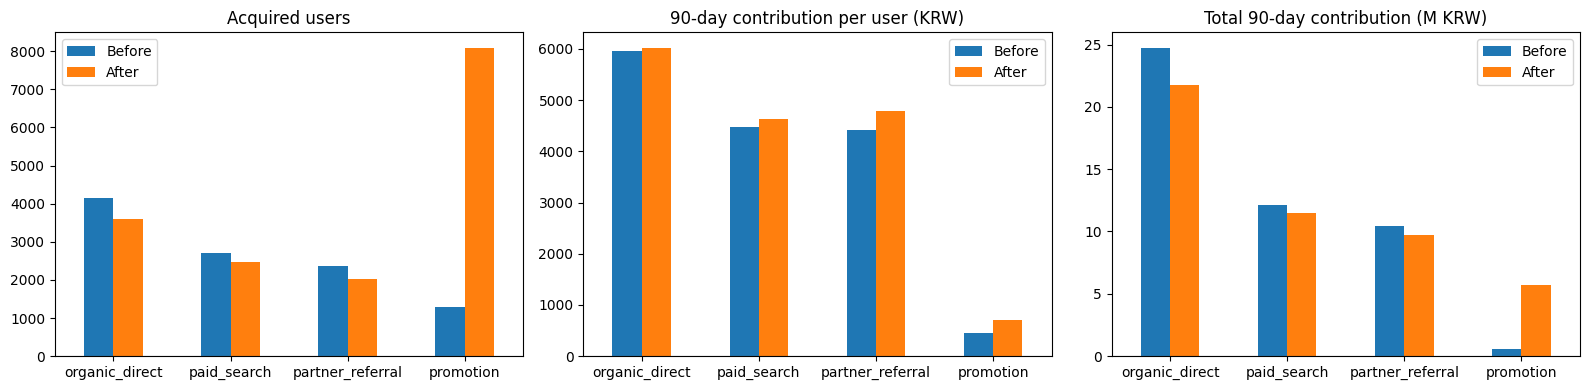

In [7]:
# §3-B 시각화: 총 기여 = 가입자 수 × 1인당 기여 — Before vs After (수정하지 말고 실행)
panels = [("acquired_users", "Acquired users", 1),
          ("contribution_per_user", "90-day contribution per user (KRW)", 1),
          ("contribution", "Total 90-day contribution (M KRW)", 1e6)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title, scale) in zip(axes, panels):
    pd.DataFrame({p: by_channel[p][col] / scale for p in PERIODS}).plot(kind="bar", ax=ax, title=title)
    ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 3-C. North Star 연결: 월 완료 박 수 중 프로모션 비중 (실행만)

발표의 North Star는 **월간 완료된 숙박 박 수**였습니다. 이 박 수 중 프로모션으로 획득한 고객의 몫이 얼마나 되는지 봅니다.

acquisition_channel,organic_direct,paid_search,partner_referral,promotion,total,promotion_share
month,,,,,,
2025-03,295,219,135,24,673,3.6%
2025-04,553,359,264,64,"1,240",5.2%
2025-05,655,414,345,71,"1,485",4.8%
2025-06,671,452,355,84,"1,562",5.4%
2025-07,815,594,373,70,"1,852",3.8%
2025-08,844,621,450,122,"2,037",6.0%
2025-09,806,580,403,130,"1,919",6.8%
2025-10,866,670,416,146,"2,098",7.0%
2025-11,818,585,378,143,"1,924",7.4%


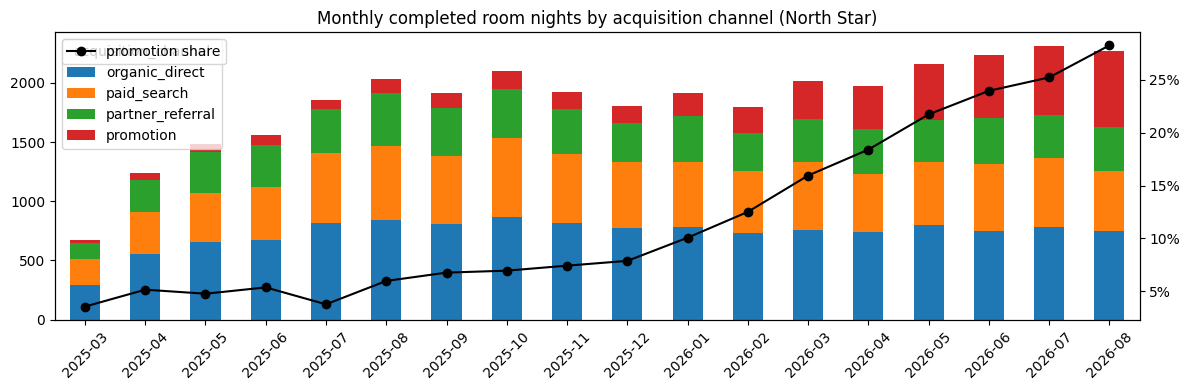

※ 2025-03은 서비스 출시 직후라 박 수가 적습니다. 같은 달끼리 비교하세요 (예: 2025-08 vs 2026-08).


In [8]:
# ── §3-C. North Star 연결: 월 완료 박 수 중 프로모션 비중 (수정하지 말고 실행) ───
comp = book[book["status_at_cutoff"] == "completed"].copy()
comp["month"] = comp["completed_at"].dt.to_period("M").astype(str)
nsm = comp.pivot_table(index="month", columns="acquisition_channel", values="nights", aggfunc="sum", fill_value=0)
nsm["total"] = nsm.sum(axis=1)
nsm["promotion_share"] = nsm["promotion"] / nsm["total"]
display(nsm.style.format({**{c: "{:,}" for c in nsm.columns if c != "promotion_share"}, "promotion_share": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(12, 4))
nsm.drop(columns=["total", "promotion_share"]).plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Monthly completed room nights by acquisition channel (North Star)")
ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx()
ax2.plot(range(len(nsm)), nsm["promotion_share"], color="black", marker="o", label="promotion share")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()
print("※ 2025-03은 서비스 출시 직후라 박 수가 적습니다. 같은 달끼리 비교하세요 (예: 2025-08 vs 2026-08).")

### ❓ Q3

1. **3-A만 보면** 어떤 결론이 나오나요? **3-B와 3-C를 보면** 그 결론이 어떻게 바뀌나요? "**수준(1인당·비율) vs 총량**"이라는 말로 설명하세요.
2. 프로모션을 지금 **절반으로 줄이면** 3-B의 총 기여와 3-C의 완료 박 수에 어떤 영향이 예상되나요? 대략의 크기를 추정하고, **그 추정이 성립하려면 어떤 가정이 필요한지** 쓰세요.
3. **H1을 판정**하세요. 이 시점의 잠정 결론은 무엇인가요?

**A.** 1. 프로모션의 재예약률은 6.9%로 다른 채널보다 낮지만, 가입자가 1,279명에서 8,091명으로 증가하면서 90일 총 기여는 약 57만 원에서 569만 원으로 증가했다. 따라서 고객당 반복 구매 성과는 낮아도 유입 규모를 통해 총 기여를 높일 수 있다. 2. 다른 채널이 그대로이고 프로모션의 비용과 기여가 비례해서 감소한다고 가정하면, 전체 90일 기여는 약 4,575만 원으로 감소한다. 완료 박 수도 줄어들 것으로 예상된다. 다만 실제 고객의 채널 이동과 비용 변화는 알 수 없으므로 단순 추정이다. 3. H1은 관찰 데이터에서 지지된다. 프로모션은 재예약률이 낮지만, 획득 고객 증가로 총 기여와 완료 박 수가 증가했다. 다만 전체 90일 기여는 약 4,787만 원에서 4,859만 원으로 소폭 증가하는 데 그쳤으므로, 프로모션의 실제 순증 효과는 추가 검증이 필요하다.

---
# §4. 순증 점검 — H2

§3의 총 기여 계산에는 숨은 가정이 하나 있습니다. **프로모션으로 온 고객은 프로모션이 없었다면 오지 않았을 것**이라는 가정입니다. 이 가정을 점검합니다.

## 4-A. 전체 총량은 정말 늘었나?

In [9]:
# ── §4-A. 전체 총량 점검: 기여는 정말 늘었나? ───────────────────────────────
change = pd.DataFrame({
    "Before": by_channel["Before"]["contribution"],
    "After":  by_channel["After"]["contribution"],
})
change["diff"] = change["After"] - change["Before"]                    # After − Before
change.loc["TOTAL"] = change.sum()
display(change.style.format(WON))
self_check("§4-A 전체 기여 증감", f'{change.loc["TOTAL", "diff"]:.0f}', "5c3ebc9b100d")

signups = pd.Series({p: by_channel[p]["acquired_users"].sum() for p in PERIODS})
print(f"가입자 수: {signups['Before']:,} → {signups['After']:,} ({signups['After']/signups['Before']-1:+.0%})")

non_promo = nsm.drop(columns=["promotion", "total", "promotion_share"]).sum(axis=1)
print(f"프로모션 외 채널의 월 완료 박 수: 2025-08 {non_promo['2025-08']:,} → 2026-08 {non_promo['2026-08']:,}")

,Before,After,diff
acquisition_channel,,,
organic_direct,"24,740,849","21,721,157","-3,019,692"
paid_search,"12,138,757","11,493,141","-645,616"
partner_referral,"10,424,572","9,689,319","-735,253"
promotion,"567,657","5,690,601","5,122,944"
TOTAL,"47,871,835","48,594,218","722,383"


✅ §4-A 전체 기여 증감
가입자 수: 10,500 → 16,200 (+54%)
프로모션 외 채널의 월 완료 박 수: 2025-08 1,915 → 2026-08 1,626


## 4-B. 순증 비율 시나리오

이 데이터에는 프로모션을 **받지 않은 비교 집단(대조군)** 이 없어서 순증 비율을 직접 잴 수 없습니다. 대신 "순증 비율이 r이라면?"으로 결론이 얼마나 흔들리는지 봅니다.

- 가정: 순증 비율이 r이면, 프로모션 획득 고객 중 (1 − r)은 **광고 없이도 같은 기여를 냈을 사람**이다.
- 순증 기여 = r × (광고비 차감 전 기여) − 광고비
- **손익분기 순증 비율 r\*** = 광고비 ÷ 광고비 차감 전 기여 → 순증 비율이 r\*보다 높아야 광고비를 회수한다.

프로모션(After) 광고비 차감 전 기여: 12,163,935원 / 광고비: 6,473,334원
r = 50%일 때 순증 기여: -391,366원
손익분기 순증 비율 r* = 53.2%
✅ §4-B r*


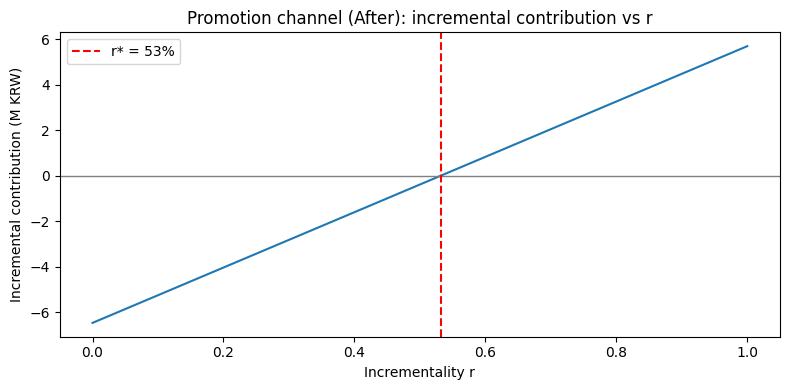

In [10]:
# ── §4-B. 순증 비율 시나리오 ────────────────────────────────────────────────
# 가정: 순증 비율이 r이면, 프로모션 획득 고객 중 (1 − r)은 광고 없이도 '같은 기여'를 냈을 사람이다.
#   순증 기여 = r × (광고비 차감 전 기여) − 광고비
#   손익분기 순증 비율 r* = 광고비 / 광고비 차감 전 기여

promo = by_channel["After"].loc["promotion"]
r = 0.5
incremental_at_50 = r * promo["contribution_before_media"] - promo["media_cost"]
r_star = promo["media_cost"] / promo["contribution_before_media"]

print(f"프로모션(After) 광고비 차감 전 기여: {promo['contribution_before_media']:,.0f}원 / 광고비: {promo['media_cost']:,.0f}원")
print(f"r = 50%일 때 순증 기여: {incremental_at_50:,.0f}원")
print(f"손익분기 순증 비율 r* = {r_star:.1%}")
self_check("§4-B r*", f"{r_star:.3f}", "686314406c02")

rs = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rs, (rs * promo["contribution_before_media"] - promo["media_cost"]) / 1e6)
ax.axhline(0, color="gray", lw=1); ax.axvline(r_star, color="red", ls="--", label=f"r* = {r_star:.0%}")
ax.set_xlabel("Incrementality r"); ax.set_ylabel("Incremental contribution (M KRW)")
ax.set_title("Promotion channel (After): incremental contribution vs r"); ax.legend()
plt.tight_layout(); plt.show()

### ❓ Q4

1. 4-A에서 프로모션 기여는 크게 늘었는데 **전체 기여는 거의 그대로**입니다. 가능한 설명을 **2가지** 쓰세요. 지금 데이터만으로 둘을 구분할 수 있나요?
2. 프로모션 채널의 **r\*** 값의 의미를 한 문장으로 쓰세요. 이 값으로 볼 때 §3의 "프로모션 채널을 유지해야 한다"는 결론은 얼마나 튼튼한가요?
3. **H2를 판정**하세요(지지 / 기각 / 판정 불가). 판정 불가라면, 판정하려면 무엇이 필요한지 쓰세요.


**A.** 1. 기존 자연 유입 고객이 프로모션으로 이동하는 채널 잠식이 발생했을 가능성이 있다. 다른 채널의 독립적인 성과 하락이 프로모션 기여 증가분을 상쇄했을 가능성이 있다. 2. 손익분기 순증 비율은 **53.2%**로, 실제 순증 비율이 이를 초과해야 광고비를 회수할 수 있다. 50%를 가정하면 약 39만 원의 손실이 발생하므로, §3에서 확인한 총 기여 증가만으로 프로모션 유지가 타당하다고 확정할 수 없다. 3. H2는 판정 불가이다. 기존 채널 잠식 가능성은 확인되지만 실제 순증 비율은 알 수 없다. 프로모션 노출군과 비노출군을 비교하는 실험이 필요하다.

---
# §5. 더 쪼개 보기 — H4

지금까지는 "프로모션"을 하나의 채널로 묶어서 봤습니다. 그런데 프로모션 채널 안에는 캠페인이 두 개(**promo_destination**, **promo_open**) 있습니다. 지금까지 본 프로모션 숫자(1인당 기여, r\* 등)는 이 둘을 합친 **평균**입니다. 발표에서 전체 CVR을 채널로 쪼개 구성 차이를 찾았듯이, 프로모션 채널도 한 단계 더 쪼개 봅니다.

| 가설 | 내용 | 검증에 쓸 지표 |
|---|---|---|
| **H4** | 프로모션은 캠페인 두 개를 합친 것이라, 캠페인마다 성과가 다를 것이다. 합친 평균이 플러스여도 그 안에 마이너스 캠페인이 숨어 있을 수 있다 | 캠페인별 90일 기여(총액/1인당), 손익분기 순증 비율 r\* |

## 5-A. 캠페인 단위 90일 기여 + 손익분기 순증 비율

여기서는 한 가지 쪼개기 방법으로 **최초 획득 캠페인**을 봅니다. §3-B의 함수를 그대로 쓰되 묶는 기준만 바꿉니다. `r_star`는 캠페인별 손익분기 순증 비율, `incremental_at_50`은 순증 비율 50%일 때의 순증 기여입니다.

In [11]:
# ── §5-A. 캠페인 단위 90일 기여 + 손익분기 순증 비율 ───────────────────────────
# 힌트: contribution_table의 by 인자에 '최초 획득 캠페인' 컬럼명을 넣습니다.
by_campaign = {p: contribution_table(per_user[p], p, "acq_campaign") for p in PERIODS}

for p in PERIODS:
    t = by_campaign[p].copy()
    t["r_star"] = np.where(t["media_cost"] > 0, t["media_cost"] / t["contribution_before_media"], np.nan)
    t["incremental_at_50"] = 0.5 * t["contribution_before_media"] - t["media_cost"]
    by_campaign[p] = t
    print(f"[{p}]")
    display(t.sort_values("contribution_per_user").style.format({**CONTRIB_FMT, "r_star": "{:.0%}", "incremental_at_50": WON}, na_rep="-"))
self_check("§5-A After promo_open 기여", f'{by_campaign["After"].loc["promo_open", "contribution"]:.0f}', "fa4a35d035c8")

[Before]


,acquired_users,first_pay_rate,commission,coupon,payment_cost,cancel_cost,contribution_before_media,completed_bookings,media_cost,contribution,contribution_per_user,media_per_user,r_star,incremental_at_50
acq_campaign,,,,,,,,,,,,,,
promo_open,768,8.5%,"1,266,636","490,500","192,578",750,"582,808",62,"999,573","-416,765",-543,"1,302",172%,"-708,169"
promo_destination,511,16.0%,"1,959,492","182,500","312,739","1,250","1,463,003",82,"478,581","984,422","1,926",937,33%,"252,920"
search_category,"1,509",34.1%,"10,819,116","108,000","1,950,962","18,750","8,741,404",502,"2,832,900","5,908,504","3,916","1,877",32%,"1,537,802"
partner_program,"2,356",28.5%,"14,843,376","109,500","2,491,342","14,750","12,227,784",689,"1,803,212","10,424,572","4,425",765,15%,"4,310,680"
search_brand,"1,207",34.6%,"9,357,156","73,500","1,552,126","9,500","7,722,030",432,"1,491,777","6,230,253","5,162","1,236",19%,"2,369,238"
organic,"4,149",31.7%,"29,996,820","235,500","4,990,971","29,500","24,740,849","1,392",0,"24,740,849","5,963",0,-,"12,370,424"


[After]


,acquired_users,first_pay_rate,commission,coupon,payment_cost,cancel_cost,contribution_before_media,completed_bookings,media_cost,contribution,contribution_per_user,media_per_user,r_star,incremental_at_50
acq_campaign,,,,,,,,,,,,,,
promo_open,"4,844",8.4%,"7,697,832","3,061,500","1,211,183","7,250","3,417,899",373,"4,887,635","-1,469,736",-303,"1,009",143%,"-3,178,686"
promo_destination,"3,247",16.0%,"11,888,100","1,185,500","1,947,064","9,500","8,746,036",514,"1,585,699","7,160,337","2,205",488,18%,"2,787,319"
search_category,"1,343",34.0%,"9,756,492","91,500","1,701,797","12,250","7,950,945",452,"2,562,091","5,388,854","4,013","1,908",32%,"1,413,382"
partner_program,"2,022",28.6%,"13,671,024","109,500","2,279,651","12,000","11,269,873",588,"1,580,554","9,689,319","4,792",782,14%,"4,054,382"
search_brand,"1,137",35.3%,"9,194,820","64,500","1,593,580","11,000","7,525,740",397,"1,421,453","6,104,287","5,369","1,250",19%,"2,341,417"
organic,"3,607",31.3%,"26,426,340","228,000","4,454,433","22,750","21,721,157","1,164",0,"21,721,157","6,022",0,-,"10,860,578"


✅ §5-A After promo_open 기여


## 5-B. 두 프로모션 캠페인의 기여 분해

세 가지로 나눠 봅니다.
1. 1인당 기여를 항목별로 나눠, 두 프로모션 캠페인의 차이가 **어느 항목에서** 나오는지
2. 수수료 차이가 **예약 수(전환)** 때문인지 **예약당 단가** 때문인지
3. 기여가 낮은 캠페인에서, 행동이 그대로라고 할 때 쿠폰을 얼마까지 바꾸면 손익분기인지

,promo_destination,promo_open,diff
commission,"3,661","1,589","-2,072"
coupon,-365,-632,-267
payment_cost,-600,-250,350
cancel_cost,-3,-1,1
media_cost,-488,"-1,009",-521
TOTAL (per user),"2,205",-303,"-2,509"


,completed_bookings_per_user,commission_per_completed_booking
acq_campaign,,
promo_destination,0.158,"23,129"
promo_open,0.077,"20,638"


✅ §5-B 1인당 기여 차이 합계
✅ §5-B promo_open 완료 예약당 수수료


,session_campaign,platform_coupon_krw,bookings
0,organic,0,10448
1,organic,1500,1405
2,partner_program,0,3902
3,partner_program,1500,513
4,promo_destination,2500,1864
5,promo_open,9000,1287
6,search_brand,0,2754
7,search_brand,1500,366
8,search_category,0,3212
9,search_category,1500,462


promo_open 손실 1,469,736원 · 9,000원 쿠폰 완료 예약 339건 → 손익분기 쿠폰 ≈ 4,578원


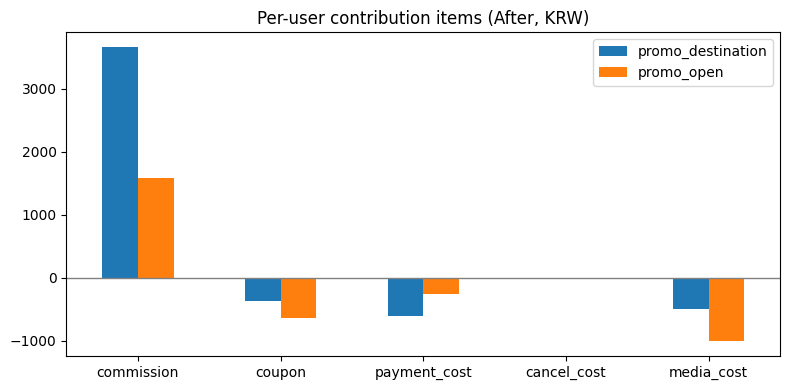

In [12]:
# ── §5-B. 두 프로모션 캠페인의 기여 분해 ───────────────────────────────────────
a = by_campaign["After"]
items = ["commission", "coupon", "payment_cost", "cancel_cost", "media_cost"]
sign = pd.Series({"commission": 1, "coupon": -1, "payment_cost": -1, "cancel_cost": -1, "media_cost": -1})

# (1) 1인당 기여 항목 분해
decomp = pd.DataFrame({c: a.loc[c, items] * sign / a.loc[c, "acquired_users"] for c in ["promo_destination", "promo_open"]})
decomp.loc["TOTAL (per user)"] = decomp.sum()
decomp["diff"] = decomp["promo_open"] - decomp["promo_destination"]                    # promo_open − promo_destination
display(decomp.style.format("{:,.0f}"))

# (2) 수수료 차이의 출처: 1인당 완료 예약 수 × 완료 예약당 수수료
src = pd.DataFrame({
    "completed_bookings_per_user": a["completed_bookings"] / a["acquired_users"],
    "commission_per_completed_booking": a["commission"] / a["completed_bookings"],
}).loc[["promo_destination", "promo_open"]]
display(src.style.format({"completed_bookings_per_user": "{:.3f}", "commission_per_completed_booking": "{:,.0f}"}))
self_check("§5-B 1인당 기여 차이 합계", f'{decomp.loc["TOTAL (per user)", "diff"]:.0f}', "5f220129c11c")
self_check("§5-B promo_open 완료 예약당 수수료", f'{src.loc["promo_open", "commission_per_completed_booking"]:.0f}', "13d39e8fe4fc")

# (3) 손익분기 쿠폰 (쿠폰을 바꿔도 고객 행동이 그대로라는 가정)
#   먼저 세션 캠페인별로 실제 지급된 쿠폰 금액을 확인합니다.
coupon_by_campaign = (book.merge(sessions[["session_id", "campaign_id"]], on="session_id")
                          .assign(session_campaign=lambda d: d["campaign_id"].fillna("organic"))
                          .groupby(["session_campaign", "platform_coupon_krw"]).size().rename("bookings").reset_index())
display(coupon_by_campaign)

d = DETAIL["After"]; d = d[d["acq_campaign"] == "promo_open"]
PROMO_COUPON = 9000                       # 위 표: promo_open 세션의 예약은 모두 9,000원 쿠폰
is_promo_coupon = d["platform_coupon_krw"] == PROMO_COUPON
n_done = (d["done"] & is_promo_coupon).sum()
n_paid = (d["paid"] & is_promo_coupon).sum()
loss = -a.loc["promo_open", "contribution"]
# 쿠폰을 1원 줄이면: 숙박 완료 예약의 쿠폰 비용 −1원, 고객 결제액이 1원 늘어 결제처리비(결제액의 1.8%, DATA_DICTIONARY) +0.018원
breakeven_coupon = PROMO_COUPON - loss / (n_done - 0.018 * n_paid)
print(f"promo_open 손실 {loss:,.0f}원 · 9,000원 쿠폰 완료 예약 {n_done:,}건 → 손익분기 쿠폰 ≈ {breakeven_coupon:,.0f}원")

fig, ax = plt.subplots(figsize=(8, 4))
decomp.drop(index="TOTAL (per user)")[["promo_destination", "promo_open"]].plot(kind="bar", ax=ax)
ax.axhline(0, color="gray", lw=1); ax.set_title("Per-user contribution items (After, KRW)")
ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 5-C. 어디서 막히는가 — 획득 캠페인별 세션 퍼널 (실행만)

After 기간의 세션을 **세션 주인의 최초 획득 캠페인**으로 묶어 단계별 전환율을 봅니다. (§2 ~ §5와 같은 획득 축)

,→ list_view,→ detail_view,→ room_select,→ checkout_start,→ payment_complete,search → payment CVR,search_sessions
acq_campaign,,,,,,,
organic,94.0%,69.3%,73.7%,68.2%,41.9%,13.7%,"12,412"
partner_program,93.8%,70.4%,73.9%,67.1%,36.6%,12.0%,"6,935"
promo_destination,94.2%,58.3%,66.8%,64.3%,28.1%,6.6%,"8,806"
promo_open,94.0%,58.5%,67.3%,63.8%,14.4%,3.4%,"12,720"
search_brand,94.6%,73.6%,77.1%,70.8%,42.7%,16.2%,"3,578"
search_category,95.0%,70.8%,74.1%,70.6%,43.2%,15.2%,"4,351"


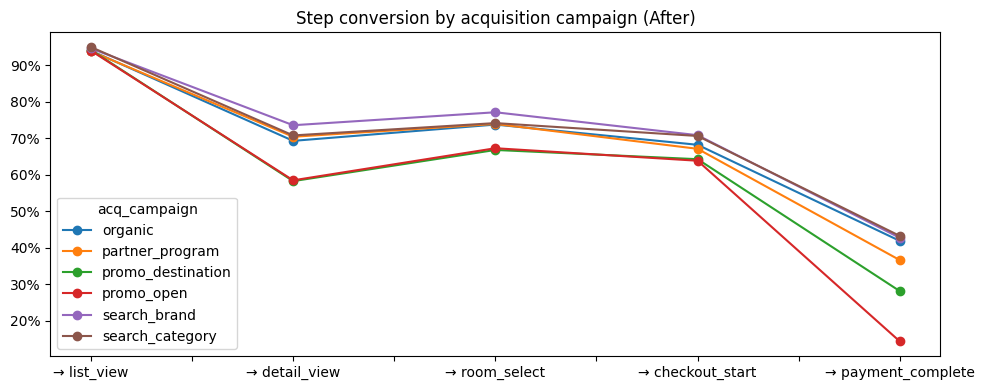

In [13]:
# ── §5-C. 어디서 막히는가: 획득 캠페인별 세션 퍼널 (After, 수정하지 말고 실행) ───
after_sessions = (sessions[in_period(sessions["started_at"], "After")][["session_id", "user_id"]]
                  .merge(users[["user_id", "acq_campaign"]], on="user_id"))
reached = (events[events["session_id"].isin(after_sessions["session_id"])]
           .drop_duplicates(["session_id", "event_name"])
           .merge(after_sessions[["session_id", "acq_campaign"]], on="session_id"))
funnel = (reached.pivot_table(index="acq_campaign", columns="event_name", values="session_id", aggfunc="count")
                 .reindex(columns=STAGES).fillna(0))
step = funnel.div(funnel.shift(axis=1)).drop(columns="search")
step.columns = [f"→ {c}" for c in step.columns]
step["search → payment CVR"] = funnel["payment_complete"] / funnel["search"]
step["search_sessions"] = funnel["search"]
display(step.style.format({**{c: "{:.1%}" for c in step.columns if c != "search_sessions"}, "search_sessions": "{:,.0f}"}))

step.drop(columns=["search → payment CVR", "search_sessions"]).T.plot(marker="o", figsize=(10, 4),
                                                                      title="Step conversion by acquisition campaign (After)")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

### ❓ Q5

1. **H4를 판정**하세요. 5-A의 `r_star`를 근거로, §3과 §4의 결론을 어떻게 수정해야 하는지 쓰세요.
2. "기여가 낮은 캠페인은 쿠폰을 줄이면 해결된다"는 주장을 평가하세요. 5-B의 (1)(2)(3)을 모두 근거로 써서 **맞는 부분**과 **부족한 부분**을 나눠 쓰세요.
3. 5-C에서 두 프로모션 캠페인의 차이가 가장 큰 단계는 어디인가요? 이 결과는 5-B (2)와 어떻게 연결되나요? 이 로그만으로 이탈의 **원인**을 확정할 수 있나요?


**A.** 1. H4는 지지된다. promo_open의 총 기여는 -147만 원, 손익분기 순증 비율은 143%인 반면, promo_destination은 +716만 원, 18%이다. 따라서 §3의 프로모션 유지 결론을 수정하여 캠페인별로 차등 운영해야 한다. 2. 맞는 부분: promo_open의 쿠폰을 9,000원에서 약 4,578원으로 줄이면 다른 조건이 일정할 때 손익분기가 가능하다. 부족한 부분: promo_open은 1인당 수수료가 2,072원 낮고, 완료 예약 수도 0.077건으로 적으며, 광고비도 521원 더 높다. 따라서 쿠폰 축소만으로 문제 해결을 보장할 수 없다. 3. 가장 큰 차이는 checkout_start → payment_complete 단계로, promo_destination 28.1%, promo_open 14.4%로 13.7%p 차이가 난다. 이는 promo_open의 낮은 완료 예약 수와 연결된다. 다만 로그만으로 이탈 원인이 쿠폰, 가격 또는 결제 과정 때문인지 확정할 수 없다.

---
# §6. 판정과 운영 제안

처음 질문에 답합니다. **"프로모션을 줄이는 게 맞는가?"**

## 6-A. 가설 판정표

| 가설 | 판정 (지지 / 기각 / 판정 불가) | 핵심 수치 근거 (본인 출력값) | 이 결과만 보고 결정했다면 생겼을 오판 |
|---|---|---|---|
| H1 | 지지 | 프로모션 총 기여 57만 → 569만 원, 완료 박 수 122 → 640박(8월 비교) | 낮은 재예약률(6.9%)만 보고 축소 |
| H2 | 판정 불가 | 전체 기여는 72만 원만 증가, 손익분기 순증 비율 53.2% | 관찰된 기여를 모두 순증 효과로 판단 |
| H3 | 기각 | 프로모션 취소율 6.7%로 다른 채널(7.1~9.7%)보다 낮음 | 낮은 CVR만으로 예약 품질이 나쁘다고 판단 |
| H4 | 지지 | promo_open 총 기여 -147만 원(r*=143%), promo_destination +716만 원(r*=18%) | 프로모션 전체를 동일하게 운영|

§1에서 정한 판단 기준을 중간에 바꿨다면, **무엇을 왜 바꿨는지** 적으세요:
§1에서 정한 90일 관찰 기여 기준은 유지하되, 실제 순증 효과를 확인할 수 없다는 한계를 반영해 캠페인별 기여와 손익분기 순증 비율을 추가로 고려하였다.
## 6-B. 운영안

- **제안** (유지 / 확대 / 축소 / 일부 조정 — 캠페인별로): 캠페인별 일부 조정
- **가장 중요한 수치 근거 2~3개**: promo_destination은 총 기여 +716만 원, promo_open은 -147만 원이다. 손익분기 순증 비율은 각각 18%, 143%로 차이가 크다. 결제 단계 전환율도 28.1%와 14.4%로 13.7%p 차이가 난다.

## 6-C. 지표 설계 (분자 / 분모 / 집계 단위 / 기간이 모호하지 않게)

| 역할 | 제안 지표 | 정의 | 왜 필요한가 |
|---|---|---|---|
| Primary | 가입 후 90일 1인당 기여 | (90일 수수료 − 쿠폰 − 처리비 − 광고비) ÷ 신규 가입자 수. 최초 획득 캠페인별 가입 코호트 기준 | 캠페인별 수익성 판단 |
| Diagnostic | 결제 단계 전환율 | 결제 완료 세션 수 ÷ 결제 시작 세션 수. 캠페인별·월별 집계 | 결제 단계의 전환 병목 확인 |
| Guardrail | 예약 취소율 | 취소 예약 수 ÷ 관찰이 완료된 결제 예약 수. 캠페인별·월별 집계 | 비용 개선 시 예약 품질 악화 방지 |

## 6-D. 검증 실험 설계

한 개의 실험만, 각 칸 1~2줄로 간단히 쓰세요.

| 항목 | 작성 |
|---|---|
| 검증할 가설 | 프로모션 제공은 비제공 대비 실제 순증 기여를 증가시킨다. |
| 처치 / 대조 | 처치군: 기존 프로모션 제공 / 대조군: 프로모션 미제공 |
| 무작위 단위와 오염 위험 | 캠페인별 적격 사용자 단위 무작위 배정. 쿠폰 공유 및 다른 채널을 통한 프로모션 노출 가능성을 관리한다. |
| Primary · Guardrail 지표 | Primary: 배정된 사용자 1인당 90일 순기여 차이 / Guardrail: 예약 취소율 |
| 관찰 기간과 성공 / 중단 기준 | 마지막 배정자까지 90일 관찰. 순증 기여가 통계적으로 양수이고 취소율이 허용 범위 내이면 유지·확대, 그렇지 않으면 축소를 검토한다. |

###고생 많으셨습니다 :)